# arXiv embeddings at scale

This notebook consumes the sample and prepared text vectors made by [Prepare the arXiv dataset](dataset_setup/prepare_arxiv_dataset.ipynb). It fits UMAP and a multilevel-initialized IMSTE layout, then applies gravity and mean shift to produce the final IMSTE coordinates. The estimator returns both the base layout and the final refined layout; the comparison figure shows UMAP and final IMSTE. Gravity is feature-space based; UMAP coordinates are never used to initialize IMSTE.


## 1. Load the prepared dataset

Run `dataset_setup/prepare_arxiv_dataset.ipynb` first if prepared text vectors are missing or you want a larger sample. Here, increasing or changing model settings does not download or re-embed text; this notebook reads the one prepared cache.

In [1]:
%load_ext autoreload
%autoreload 2

%config InlineBackend.figure_format = 'retina'

from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
from IPython.display import display

PROJECT_ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "pyproject.toml").is_file()
     and (path / "imste" / "__init__.py").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise RuntimeError("Could not locate the IMSTE repository from the notebook working directory.")
for local_path in (PROJECT_ROOT, PROJECT_ROOT / "notebooks" / "src"):
    local_path = str(local_path)
    if local_path in sys.path:
        sys.path.remove(local_path)
    sys.path.insert(0, local_path)
import imste
if not Path(imste.__file__).resolve().is_relative_to(PROJECT_ROOT.resolve()):
    raise RuntimeError(
        f"This kernel already loaded IMSTE from {imste.__file__}; restart the kernel and rerun from the top."
    )
DATA_DIR = PROJECT_ROOT / "data" / "arxiv"
from arxiv_dataset import load_arxiv_dataset
papers, X, data_manifest = load_arxiv_dataset(DATA_DIR)
papers_all, X_all = papers.copy(), X  # Keep the loaded source vectors intact when re-running the sampling cell.
print(f"Loaded {len(papers):,} papers × {X.shape[1]:,} features")
print(f"Vector matrix in memory: {X.nbytes / 1024**3:.2f} GiB")
print("Dataset ID:", data_manifest["dataset_id"])


Loaded 3,233,620 papers × 384 features
Vector matrix in memory: 4.63 GiB
Dataset ID: 6279205cb3ce7d1bf8df


## 2. Prepare category labels

In [2]:
# Set this to a positive integer to cap each domain, or None to use all papers.
MAX_PAPERS_PER_DOMAIN = 300_000

# Start from the prepared source matrix each time this cell runs.
papers, X = papers_all.copy(), X_all
primary_category = papers["categories"].fillna("unknown").str.split().str[0]
archive = primary_category.str.split(".").str[0]
domain_names = {
    "cs": "computer science",
    "math": "mathematics",
    "eess": "engineering",
    "stat": "statistics",
    "q-bio": "biology",
    "q-fin": "finance",
    "econ": "economics",
}
domain = archive.map(domain_names).fillna("physics")

original_n_papers = len(papers)
if MAX_PAPERS_PER_DOMAIN is not None:
    if not isinstance(MAX_PAPERS_PER_DOMAIN, int) or MAX_PAPERS_PER_DOMAIN < 1:
        raise ValueError("MAX_PAPERS_PER_DOMAIN must be a positive integer or None.")

    rng = np.random.default_rng(int(data_manifest["random_state"]))
    domain_values = domain.to_numpy()
    selected = []
    for domain_name in pd.unique(domain_values):
        domain_indices = np.flatnonzero(domain_values == domain_name)
        n_selected = min(len(domain_indices), MAX_PAPERS_PER_DOMAIN)
        selected.append(rng.choice(domain_indices, size=n_selected, replace=False))
    selected_indices = np.sort(np.concatenate(selected))

    papers = papers.iloc[selected_indices].reset_index(drop=True)
    X = X[selected_indices]
    primary_category = primary_category.iloc[selected_indices].reset_index(drop=True)
    domain = domain.iloc[selected_indices].reset_index(drop=True)


domain_order = domain.value_counts().index.tolist()
labels = pd.Categorical(domain, categories=domain_order)
print(f"Using {len(papers):,} of {original_n_papers:,} papers (max {MAX_PAPERS_PER_DOMAIN} per domain).")
display(pd.DataFrame({"primary_category": primary_category, "domain": domain}).groupby("domain", observed=True).size().sort_values(ascending=False).rename("papers"))


Using 1,113,674 of 3,233,620 papers (max 300000 per domain).


domain
computer science    300000
mathematics         300000
physics             300000
engineering          84306
statistics           66818
biology              35510
finance              13876
economics            13164
Name: papers, dtype: int64

## 3. Tune IMSTE on a smaller subset, then fit UMAP and final IMSTE

The tuning phase uses a deterministic, balanced subset capped at 250 papers per domain and a short 12-trial search. It scores domain predictability and spatial coverage on these subset embeddings; the selected settings are then used for the full-data IMSTE fit. Install the optional search dependency with `python -m pip install "imste[tuning]"` if needed. UMAP remains independently configured and does not initialize IMSTE. Gravity and mean shift run as estimator refinements inside `fit_transform`.

In [3]:
import umap

RANDOM_STATE = int(data_manifest["random_state"])
METRIC = "euclidean"  # or "cosine"
N_NEIGHBORS = 15
UMAP_EPOCHS = 200
UMAP_REPULSION_STRENGTH = 2
UMAP_SETTINGS = {
    "n_components": 2,
    "n_neighbors": N_NEIGHBORS,
    "min_dist": 0.1,
    "repulsion_strength": UMAP_REPULSION_STRENGTH,
    "metric": METRIC,
    "init": "recursive",
    "recursive_coarsening_ratio": 4,
    "compatibility_layout": False,
    "nearest_neighbor_backend": "rinnd",
    "random_state": RANDOM_STATE,
    "n_epochs": UMAP_EPOCHS,
    "verbose": True,
}

# Main IMSTE controls; all other estimator options use their defaults.
IMSTE_N_MSTS = 3
IMSTE_N_EPOCHS = 200
IMSTE_GRAVITY_STRENGTH = 0.2
IMSTE_MEAN_SHIFT_ITERATIONS = 3


In [ ]:
import time
from imste import IteratedMinimumSpanningTreeEmbedder

# Stratified by domain so the tuning subset stays balanced and reproducible.
TUNE_MAX_PER_DOMAIN = 250
TUNE_EPOCHS = 80
TUNE_TRIALS = 40
TUNE_SEARCH_SPACE = {
    "n_msts": (2, 15),
    "learning_rate": (0.01, 0.1),
    "negative_ratio": (2, 8),
    "gravity_strength": (0.0, 0.6),
    "mean_shift_iterations": (0, 4),
}

tune_rng = np.random.default_rng(RANDOM_STATE)
domain_codes = np.asarray(labels.codes)
tune_indices = []
for code in np.unique(domain_codes):
    class_indices = np.flatnonzero(domain_codes == code)
    n_selected = min(len(class_indices), TUNE_MAX_PER_DOMAIN)
    tune_indices.append(tune_rng.choice(class_indices, size=n_selected, replace=False))
tune_indices = np.sort(np.concatenate(tune_indices))
X_tune = X[tune_indices]
y_tune = np.asarray(labels.astype(str))[tune_indices]
print(f"Tuning on {len(tune_indices):,} papers across {len(np.unique(y_tune))} domains")

tune_mapper = IteratedMinimumSpanningTreeEmbedder(
    n_msts=IMSTE_N_MSTS,
    n_epochs=TUNE_EPOCHS,
    random_state=RANDOM_STATE,
    metric=METRIC,
    gravity_strength=IMSTE_GRAVITY_STRENGTH,
    mean_shift_iterations=IMSTE_MEAN_SHIFT_ITERATIONS,
)
tuning_started = time.perf_counter()
tune_result = tune_mapper.tune(
    X_tune,
    y_tune,
    search_space=TUNE_SEARCH_SPACE,
    n_samples=TUNE_TRIALS,
    n_initial_points=20,
    coverage_weight=0.4,
)
tuning_seconds = time.perf_counter() - tuning_started

IMSTE_TUNED_PARAMS = tune_result.best_params
IMSTE_N_MSTS = int(IMSTE_TUNED_PARAMS["n_msts"])
IMSTE_LEARNING_RATE = float(IMSTE_TUNED_PARAMS["learning_rate"])
IMSTE_NEGATIVE_RATIO = int(IMSTE_TUNED_PARAMS["negative_ratio"])
IMSTE_GRAVITY_STRENGTH = float(IMSTE_TUNED_PARAMS["gravity_strength"])
IMSTE_MEAN_SHIFT_ITERATIONS = int(IMSTE_TUNED_PARAMS["mean_shift_iterations"])
print(f"Best tuning accuracy: {tune_result.best_accuracy:.3f}")
print(f"Best tuning coverage: {tune_result.best_coverage:.3f}")
print("Selected IMSTE settings:", IMSTE_TUNED_PARAMS)

tuning_trials = pd.DataFrame(tune_result.x_iters, columns=TUNE_SEARCH_SPACE)
tuning_trials["accuracy"] = tune_result.cv_scores
tuning_trials["coverage"] = tune_result.coverage_scores
tuning_trials["objective"] = tune_result.objective_scores
display(tuning_trials.sort_values("objective", ascending=False).reset_index(drop=True))

Tuning on 2,000 papers across 8 domains
Best tuning accuracy: 0.660
Best tuning coverage: 0.425
Selected IMSTE settings: {'n_msts': np.int64(2), 'learning_rate': 0.1, 'negative_ratio': np.int64(2), 'gravity_strength': 2.3525138502517074e-18, 'mean_shift_iterations': np.int64(0)}


,n_msts,learning_rate,negative_ratio,gravity_strength,mean_shift_iterations,accuracy,coverage,objective
0,2,0.100000,2,2.352514e-18,0,0.6600,0.424684,0.565874
1,2,0.064537,6,1.071607e-01,0,0.6555,0.407670,0.556368
2,8,0.100000,2,0.000000e+00,0,0.6950,0.345479,0.555192
3,6,0.099881,5,3.843892e-01,0,0.7275,0.231988,0.529295
4,2,0.053723,6,2.258713e-01,1,0.6580,0.320605,0.523042
5,11,0.075793,4,3.104052e-01,1,0.7085,0.233320,0.518428
6,7,0.083925,7,7.691178e-03,2,0.6845,0.225733,0.500993
7,14,0.028771,5,5.298978e-01,0,0.7175,0.174913,0.500465
8,13,0.099391,4,1.491927e-01,3,0.7120,0.181978,0.499991
9,5,0.015142,3,4.326316e-01,2,0.6460,0.239514,0.483406


In [5]:
import time

umap_started = time.perf_counter()
Z_umap = umap.UMAP(**UMAP_SETTINGS).fit_transform(X)
umap_seconds = time.perf_counter() - umap_started
print(f"UMAP fit: {umap_seconds / 60:.1f} min")


UMAP(compatibility_layout=False, init='recursive', n_epochs=200, nearest_neighbor_backend='rinnd', random_state=42, repulsion_strength=2, verbose=True)
Fri Nov 20 12:57:20 2026 Construct fuzzy simplicial set
Fri Nov 20 12:57:20 2026 Finding Nearest Neighbors
Fri Nov 20 12:57:20 2026 Using RINND to find nearest neighbors
Building RP forest with 8 trees...
Initializing graph from 210165 leaves...
Running NN-descent for up to 20 iterations...
Iteration 1: 12341562 updates
Iteration 2: 9934720 updates
Iteration 3: 3628654 updates
Iteration 4: 1104044 updates
Iteration 5: 330749 updates
Iteration 6: 109720 updates
Iteration 7: 39737 updates
Iteration 8: 15477 updates
Converged after 8 iterations

=== Timing Breakdown ===
Forest building:    1878.127ms
Leaf initialization:1968.170ms
Candidate building:  568.504ms (8 iters)
Update iterations:  6478.240ms (8 iters)
Total measured:     10893.042ms
Fri Nov 20 12:57:32 2026 Finished Nearest Neighbor Search
Fri Nov 20 12:57:34 2026 Construct embed

/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/sklearn/utils/extmath.py:378: RuntimeWarning: divide by zero encountered in matmul
  Q, _ = normalizer(A @ Q)
/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/sklearn/utils/extmath.py:378: RuntimeWarning: overflow encountered in matmul
  Q, _ = normalizer(A @ Q)
/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/sklearn/utils/extmath.py:378: RuntimeWarning: invalid value encountered in matmul
  Q, _ = normalizer(A @ Q)
/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/sklearn/utils/extmath.py:379: RuntimeWarning: divide by zero encountered in matmul
  Q, _ = normalizer(A.T @ Q)
/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/sklearn/utils/extmath.py:379: RuntimeWarning: overflow encountered in matmul
  Q, _ = normalizer(A.T @ Q)
/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/sklearn/utils/extmath.py:379: RuntimeWarning: invalid value encountered in matmul
  Q, _ = normalizer(A.T @ Q)
/Users

Fri Nov 20 12:57:37 2026 Recursive initialization: coarsening 278418 nodes into about 69604 parts
Fri Nov 20 12:57:38 2026 Recursive initialization: coarsening 69604 nodes into about 17401 parts
Fri Nov 20 12:57:38 2026 Recursive initialization: coarsening 17401 nodes into about 4350 parts
Fri Nov 20 12:57:39 2026 Recursive initialization: coarsening 4350 nodes into about 1087 parts
Fri Nov 20 12:57:39 2026 Recursive initialization: coarsening 1087 nodes into about 271 parts


Init recursion depth 6:   0%|          | 0/275 [00:00<?, ?it/s]

Init recursion depth 5:   0%|          | 0/195 [00:00<?, ?it/s]

Init recursion depth 4:   0%|          | 0/138 [00:00<?, ?it/s]

... (3 outputs left out)

Init recursion depth 1:   0%|          | 0/50 [00:00<?, ?it/s]

Fri Nov 20 12:57:41 2026 Using adam layout optimizer


Epochs completed:   0%|            0/200 [00:00]

Fri Nov 20 12:58:25 2026 Finished embedding
UMAP fit: 1.1 min


In [6]:
import time
from imste import IteratedMinimumSpanningTreeEmbedder

imste_started = time.perf_counter()
imste_estimator = IteratedMinimumSpanningTreeEmbedder(
    n_msts=IMSTE_N_MSTS,
    learning_rate=IMSTE_LEARNING_RATE,
    negative_ratio=IMSTE_NEGATIVE_RATIO,
    n_epochs=IMSTE_N_EPOCHS,
    random_state=RANDOM_STATE,
    metric=METRIC,
    gravity_strength=IMSTE_GRAVITY_STRENGTH,
    mean_shift_iterations=IMSTE_MEAN_SHIFT_ITERATIONS,
    verbose=True
)
Z_imste = imste_estimator.fit_transform(X)
imste_seconds = imste_estimator.imste_fit_time_
gravity_seconds = imste_estimator.gravity_time_
mean_shift_seconds = imste_estimator.mean_shift_time_
imste_total_seconds = time.perf_counter() - imste_started


Fri Nov 20 12:58:27 2026 IteratedMinimumSpanningTreeEmbedder({'batch_size': 131072, 'device': 'auto', 'epsilon': 0.0001, 'gravity_core_quantile': 0.95, 'gravity_mass_power': 0.5, 'gravity_min_dist': 0.0, 'gravity_neighbors': 15, 'gravity_pack_gap_fraction': 0.25, 'gravity_pack_radius_quantile': 0.9, 'gravity_pack_regions': False, 'gravity_resolution': 1.0, 'gravity_strength': 2.3525138502517074e-18, 'include_knn_attraction': False, 'input_preprocessor': None, 'lambda_rep': 0.5, 'learning_rate': 0.1, 'logistic_margin': 1.0, 'logistic_temperature': 0.5, 'mean_shift_bandwidth_factor': 5.0, 'mean_shift_iterations': 0, 'mean_shift_neighbors': 100, 'mean_shift_step_size': 0.5, 'metric': 'euclidean', 'mst_inter_component_edges': 5, 'mst_max_neighbors': None, 'mst_method': 'famst', 'mst_neighbor_backend': 'auto', 'mst_neighbors': 15, 'mst_representatives_per_component': 10, 'multilevel_base_size': 512, 'multilevel_epochs': 1, 'multilevel_init': True, 'multilevel_reduction_ratio': 32, 'n_compon

Construct MST graph:   0%|          | 0/2 [00:00<?, ?steps/s]

Building RP forest with 8 trees...
Initializing graph from 210165 leaves...
Running NN-descent for up to 20 iterations...
Iteration 1: 12341562 updates
Iteration 2: 9934720 updates
Iteration 3: 3628654 updates
Iteration 4: 1104044 updates
Iteration 5: 330749 updates
Iteration 6: 109720 updates
Iteration 7: 39737 updates
Iteration 8: 15477 updates
Converged after 8 iterations

=== Timing Breakdown ===
Forest building:    2016.072ms
Leaf initialization:2063.070ms
Candidate building:  703.990ms (8 iters)
Update iterations:  7734.478ms (8 iters)
Total measured:     12517.610ms
Fri Nov 20 12:58:58 2026 MST graph construction complete: 31.148s


Multilevel coarsening:   0%|          | 0/1113674 [00:00<?, ?nodes/s]

Multilevel refinement epochs:   0%|          | 0/4 [00:00<?, ?epoch/s]

Fri Nov 20 12:59:09 2026 Recursive initialization: refining levels
Fri Nov 20 12:59:09 2026 Recursive initialization: refining levels
Fri Nov 20 12:59:10 2026 Recursive initialization: refining levels
Fri Nov 20 12:59:12 2026 Recursive initialization: refining levels
Fri Nov 20 12:59:13 2026 Multilevel initialization complete: 15.232s
Fri Nov 20 12:59:13 2026 Final embedding optimization


Final embedding epochs:   0%|          | 0/200 [00:00<?, ?epoch/s]

Fri Nov 20 12:59:47 2026 Final embedding optimization complete: 34.325s
Fri Nov 20 13:02:49 2026 Finished embedding
Fri Nov 20 13:02:49 2026 === Timing Breakdown ===
Fri Nov 20 13:02:49 2026 MST graph construction: 31.148s
Fri Nov 20 13:02:49 2026 Multilevel initialization: 15.232s
Fri Nov 20 13:02:49 2026 Final embedding optimization: 34.325s
Fri Nov 20 13:02:49 2026 Embedding optimization: 49.559s
Fri Nov 20 13:02:49 2026   Final MPS negative sampling and coordinate updates: 30.777s combined
Fri Nov 20 13:02:49 2026 Total measured: 264.121s
Fri Nov 20 13:02:49 2026 Multilevel initialization is included in embedding optimization.


## 4. Compare fit runtimes and render the layouts

The runtime table is followed by side-by-side Datashader views using the same domain colors and raster settings.

In [7]:
runtime_rows = [
    {"method": "IMSTE tuning (balanced subset)", "seconds": tuning_seconds},
    {"method": "UMAP", "seconds": umap_seconds},
    {"method": "IMSTE · multilevel initialization", "seconds": imste_seconds},
]
if IMSTE_GRAVITY_STRENGTH > 0 or IMSTE_MEAN_SHIFT_ITERATIONS > 0:
    runtime_rows.extend([
        {"method": "IMSTE · gravity", "seconds": gravity_seconds},
        {"method": "IMSTE · mean shift", "seconds": mean_shift_seconds},
        {"method": "IMSTE · total refined", "seconds": imste_seconds + gravity_seconds + mean_shift_seconds},
    ])
runtime_summary = pd.DataFrame(runtime_rows)
runtime_summary["runtime"] = runtime_summary["seconds"].map(
    lambda value: f"{value / 60:.1f} min" if value >= 60 else f"{value:.1f} s"
)
display(runtime_summary)


,method,seconds,runtime
0,IMSTE tuning (balanced subset),9.215133,9.2 s
1,UMAP,65.098129,1.1 min
2,IMSTE · multilevel initialization,82.775010,1.4 min
3,IMSTE · gravity,181.335145,3.0 min
4,IMSTE · mean shift,0.000000,0.0 s
5,IMSTE · total refined,264.110155,4.4 min


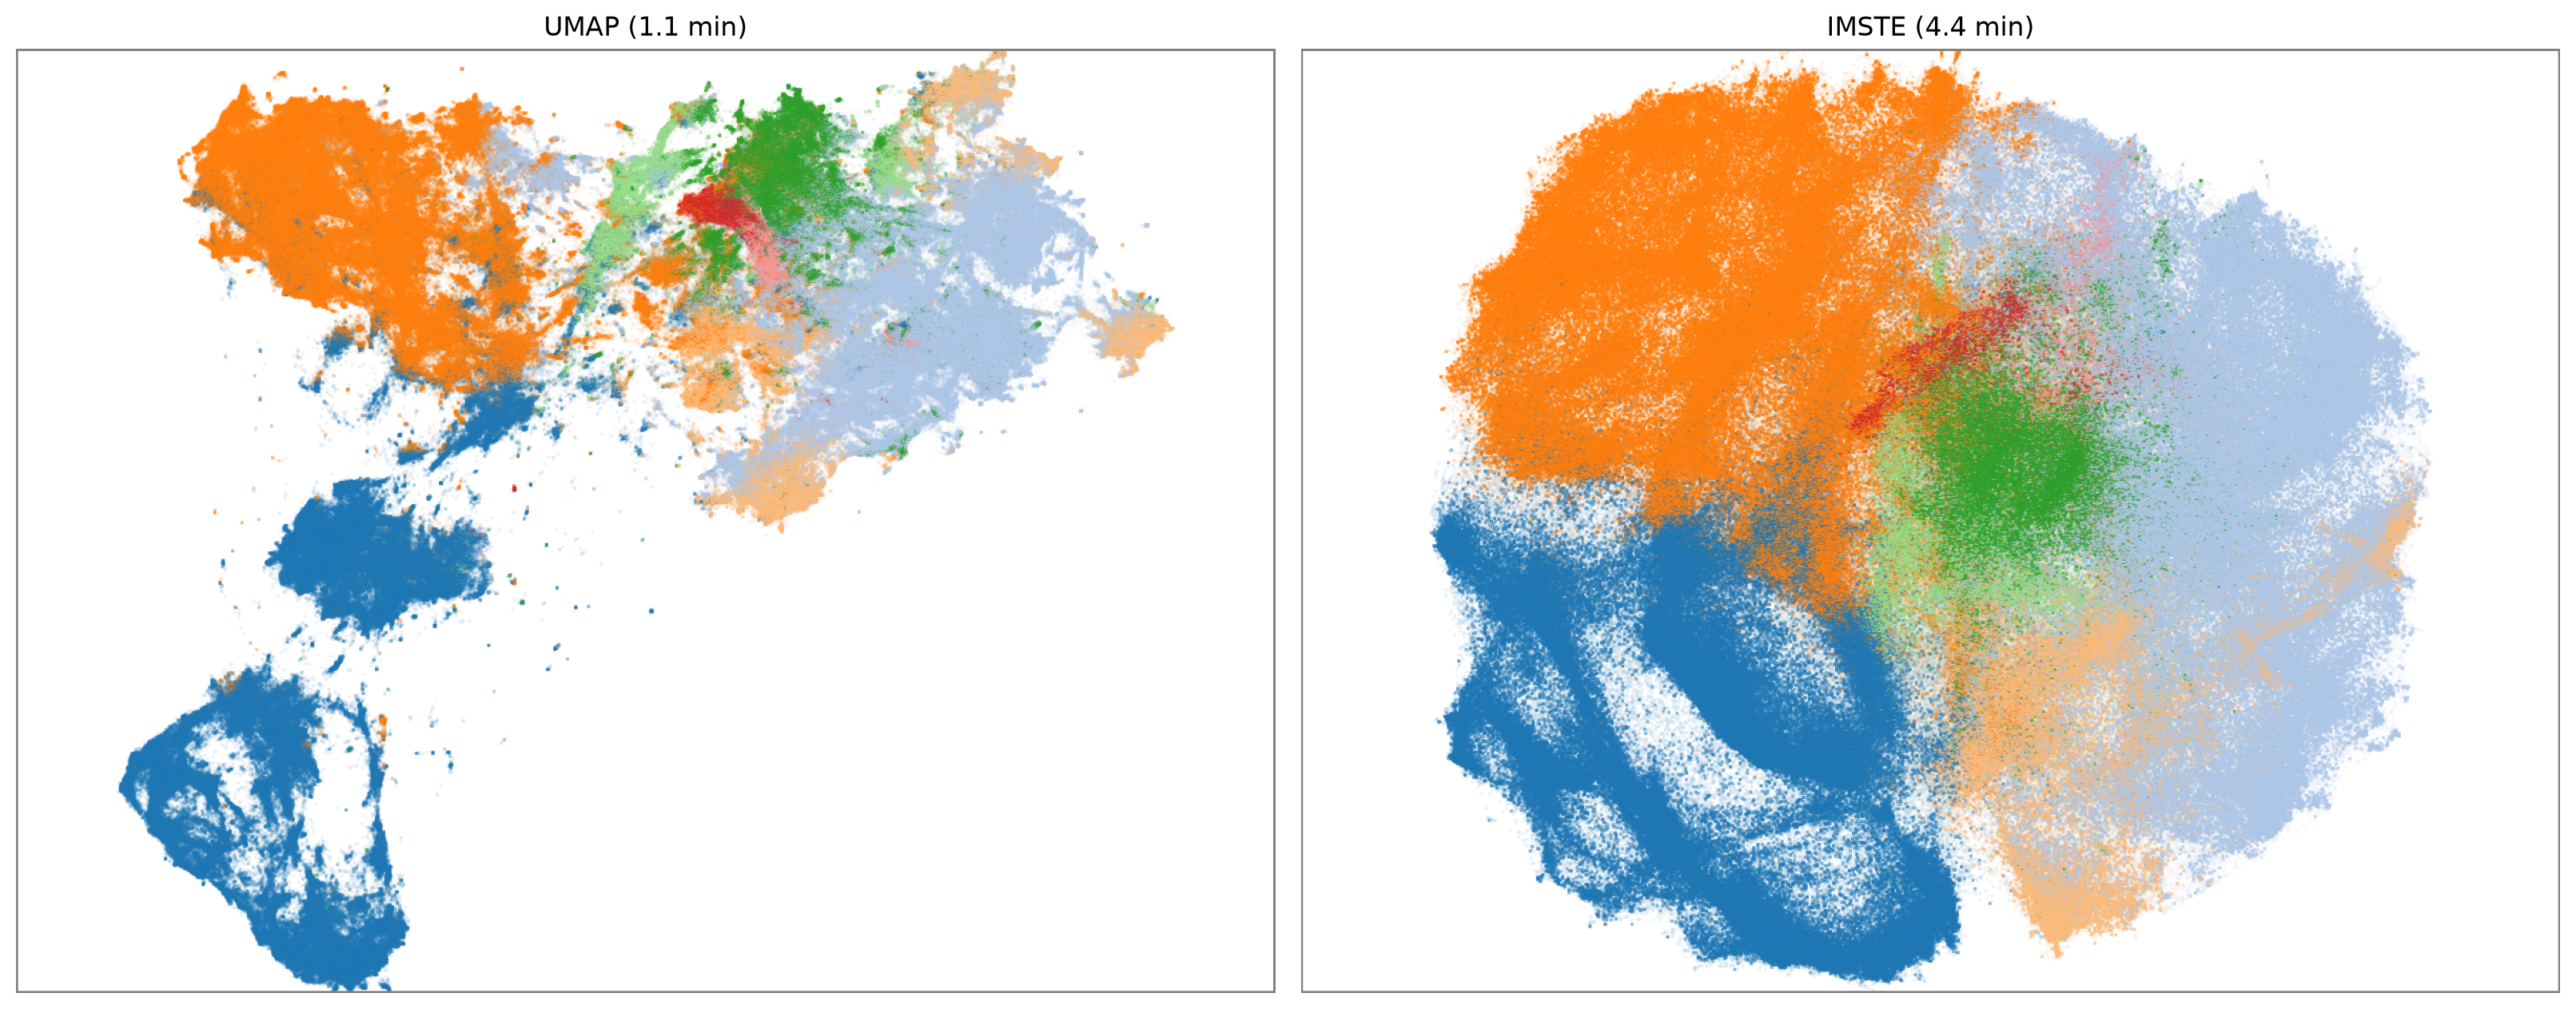

In [8]:
import matplotlib.pyplot as plt
from matplotlib.colors import to_hex
from IPython.display import display
import importlib
import imste.visualization as _imste_visualization
_imste_visualization = importlib.reload(_imste_visualization)
render_datashader_embedding = _imste_visualization.render_datashader_embedding

def render_embedding_preserving_aspect(embedding, labels=None, **kwargs):
    """Render without geometric stretching; support older IMSTE installs too."""
    import inspect
    options = dict(kwargs)
    renderer_parameters = inspect.signature(render_datashader_embedding).parameters
    if "preserve_aspect" in renderer_parameters:
        options["preserve_aspect"] = True
    else:
        coordinates = np.asarray(embedding)
        width = int(options.get("width", 1000))
        height = int(options.get("height", 1000))
        x_limits = np.asarray(
            options.get("x_range") or (coordinates[:, 0].min(), coordinates[:, 0].max()),
            dtype=np.float64,
        )
        y_limits = np.asarray(
            options.get("y_range") or (coordinates[:, 1].min(), coordinates[:, 1].max()),
            dtype=np.float64,
        )
        pixel_scale = max(
            (x_limits[1] - x_limits[0]) / width,
            (y_limits[1] - y_limits[0]) / height,
            np.finfo(np.float64).eps,
        )
        x_center, y_center = float(x_limits.mean()), float(y_limits.mean())
        options["x_range"] = (
            x_center - pixel_scale * width / 2,
            x_center + pixel_scale * width / 2,
        )
        options["y_range"] = (
            y_center - pixel_scale * height / 2,
            y_center + pixel_scale * height / 2,
        )
    return render_datashader_embedding(embedding, labels, **options)


domain_order = list(labels.categories)
palette = plt.get_cmap("tab20")
domain_color_key = {
    domain: to_hex(palette(index % palette.N))
    for index, domain in enumerate(domain_order)
}
label_values = labels.astype(str)
layouts = [
    ("UMAP", Z_umap, umap_seconds),
    ("IMSTE", Z_imste, imste_seconds + gravity_seconds + mean_shift_seconds),
]

fig, axes = plt.subplots(1, 2, figsize=(16, 7), constrained_layout=True, squeeze=False)
for ax, (method, coordinates, seconds) in zip(axes.ravel(), layouts):
    image = render_embedding_preserving_aspect(
        coordinates[:, :2], label_values, width=1200, height=900,
        color_key=domain_color_key, min_alpha=20, background="white",
        spread_px=1,
    )
    ax.imshow(image.to_pil())
    runtime = f"{seconds / 60:.1f} min" if seconds >= 60 else f"{seconds:.1f} s"
    ax.set_title(f"{method} ({runtime})")
    ax.set_axis_off()
display(fig)
plt.close(fig)
